In [ ]:
Task-1

In [ ]:
Setu and Data Loading 

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed - run: pip install xgboost  (optional)")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

xgboost not installed - run: pip install xgboost  (optional)


In [5]:
# Load the data (the dataset ships as an Excel file; a CSV copy also works)
try:
    df = pd.read_excel("Flight_Fare.xlsx")
except FileNotFoundError:
    df = pd.read_csv("Flight_Fare.csv")

print("Shape:", df.shape)
df.head()

Shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
Data Understanding and Cleaning

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 918.2 KB


In [7]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique values per column:\n", df.nunique())

Missing values:
 Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

Duplicate rows: 220

Unique values per column:
 Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64


In [8]:
for col in ["Airline", "Source", "Destination", "Total_Stops", "Additional_Info"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- Airline ---
Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64 

--- Source ---
Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64 

--- Destination ---
Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64 

--- Total_Stops ---
Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
NaN            1
4 stops        1
Name: c

In [ ]:
Feature Engineering

In [10]:
#Cleaning
df_clean = df.copy()

# 1) Missing values: only ~1 row, so dropping is safest (cannot sensibly impute Route / Total_Stops)
df_clean = df_clean.dropna().reset_index(drop=True)

# 2) Duplicates: identical rows would leak between train and test, so remove them
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df_clean)} duplicate rows. Shape now: {df_clean.shape}")

# 3) Fix inconsistent labels
df_clean["Additional_Info"] = df_clean["Additional_Info"].replace({"No Info": "No info"})
df_clean["Destination"] = df_clean["Destination"].replace({"New Delhi": "Delhi"})   # same city, two labels

Removed 220 duplicate rows. Shape now: (10462, 11)


In [11]:
data = df_clean.copy()

# --- Date of journey ---
data["Date_of_Journey"] = pd.to_datetime(data["Date_of_Journey"], format="%d/%m/%Y")
data["Journey_day"]     = data["Date_of_Journey"].dt.day
data["Journey_month"]   = data["Date_of_Journey"].dt.month
data["Journey_weekday"] = data["Date_of_Journey"].dt.dayofweek      # 0 = Monday
data["Is_weekend"]      = (data["Journey_weekday"] >= 5).astype(int)

# --- Departure time (HH:MM) ---
if "Dep_Time" in data.columns:
    dep = pd.to_datetime(data["Dep_Time"], format="%H:%M")
    data["Dep_hour"] = dep.dt.hour
    data["Dep_min"]  = dep.dt.minute

# --- Arrival time ("HH:MM" or "HH:MM DD Mon") -> keep only the clock time ---
arr = pd.to_datetime(data["Arrival_Time"].str.split(" ").str[0], format="%H:%M")
data["Arrival_hour"] = arr.dt.hour
data["Arrival_min"]  = arr.dt.minute

# --- Duration ("2h 50m", "5h", "45m") -> minutes ---
def duration_to_minutes(text):
    hours = minutes = 0
    for part in text.split():
        if part.endswith("h"):
            hours = int(part[:-1])
        elif part.endswith("m"):
            minutes = int(part[:-1])
    return hours * 60 + minutes

data["Duration_mins"] = data["Duration"].apply(duration_to_minutes)

# --- Total stops -> number ---
stops_map = {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}
data["Total_Stops"] = data["Total_Stops"].map(stops_map)

# --- Part of the day for departure ---
def part_of_day(h):
    if 5 <= h < 12:  return "Morning"
    if 12 <= h < 17: return "Afternoon"
    if 17 <= h < 21: return "Evening"
    return "Night"

if "Dep_hour" in data.columns:
    data["Dep_part_of_day"] = data["Dep_hour"].apply(part_of_day)

# --- Group very rare Additional_Info labels so they do not create noisy columns ---
vc = data["Additional_Info"].value_counts()
rare = vc[vc < 20].index
data["Additional_Info"] = data["Additional_Info"].replace(dict.fromkeys(rare, "Other"))

# --- Drop columns that are now redundant ---
# Route is fully explained by Source + Destination + Total_Stops, so it adds duplicated information.
data = data.drop(columns=["Date_of_Journey", "Route", "Duration", "Arrival_Time"] + (["Dep_Time"] if "Dep_Time" in data.columns else []))

print("Shape:", data.shape)
data.head()

Shape: (10462, 16)


,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_weekday,Is_weekend,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_mins,Dep_part_of_day
0,IndiGo,Banglore,Delhi,0,No info,3897,24,3,6,1,22,20,1,10,170,Night
1,Air India,Kolkata,Banglore,2,No info,7662,1,5,2,0,5,50,13,15,445,Morning
2,Jet Airways,Delhi,Cochin,2,No info,13882,9,6,6,1,9,25,4,25,1140,Morning
3,IndiGo,Kolkata,Banglore,1,No info,6218,12,5,6,1,18,5,23,30,325,Evening
4,IndiGo,Banglore,Delhi,1,No info,13302,1,3,4,0,16,50,21,35,285,Afternoon


In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10462 entries, 0 to 10461
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10462 non-null  str  
 1   Source           10462 non-null  str  
 2   Destination      10462 non-null  str  
 3   Total_Stops      10462 non-null  int64
 4   Additional_Info  10462 non-null  str  
 5   Price            10462 non-null  int64
 6   Journey_day      10462 non-null  int32
 7   Journey_month    10462 non-null  int32
 8   Journey_weekday  10462 non-null  int32
 9   Is_weekend       10462 non-null  int64
 10  Dep_hour         10462 non-null  int32
 11  Dep_min          10462 non-null  int32
 12  Arrival_hour     10462 non-null  int32
 13  Arrival_min      10462 non-null  int32
 14  Duration_mins    10462 non-null  int64
 15  Dep_part_of_day  10462 non-null  str  
dtypes: int32(7), int64(4), str(5)
memory usage: 1021.8 KB


In [ ]:
Task-1 Data Analysis Report

In [ ]:
Target Variable :Price

count    10462.000000
mean      9026.790289
std       4624.849541
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12344.750000
max      79512.000000
Name: Price, dtype: float64
Skewness: 1.86


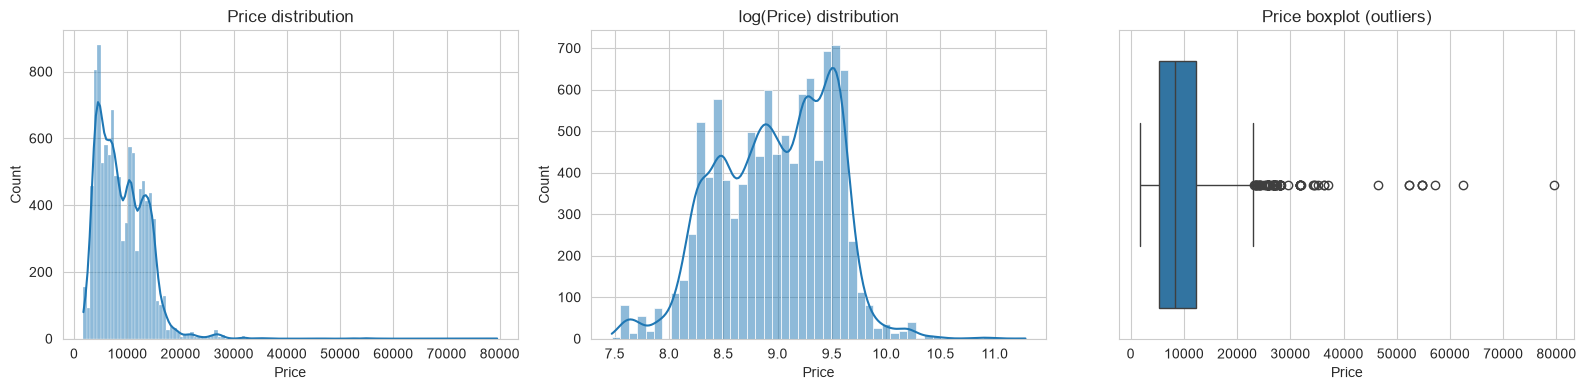

In [13]:
print(data["Price"].describe())
print("Skewness:", round(data["Price"].skew(), 2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data["Price"], kde=True, ax=ax[0]);            ax[0].set_title("Price distribution")
sns.histplot(np.log1p(data["Price"]), kde=True, ax=ax[1]);  ax[1].set_title("log(Price) distribution")
sns.boxplot(x=data["Price"], ax=ax[2]);                     ax[2].set_title("Price boxplot (outliers)")
plt.tight_layout(); plt.show()

In [14]:
q1, q3 = data["Price"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"IQR upper fence: {upper:,.0f}  |  rows above it: {(data['Price'] > upper).sum()} "
      f"({(data['Price'] > upper).mean():.1%})")

IQR upper fence: 23,026  |  rows above it: 94 (0.9%)


In [ ]:
Categerical features vs price

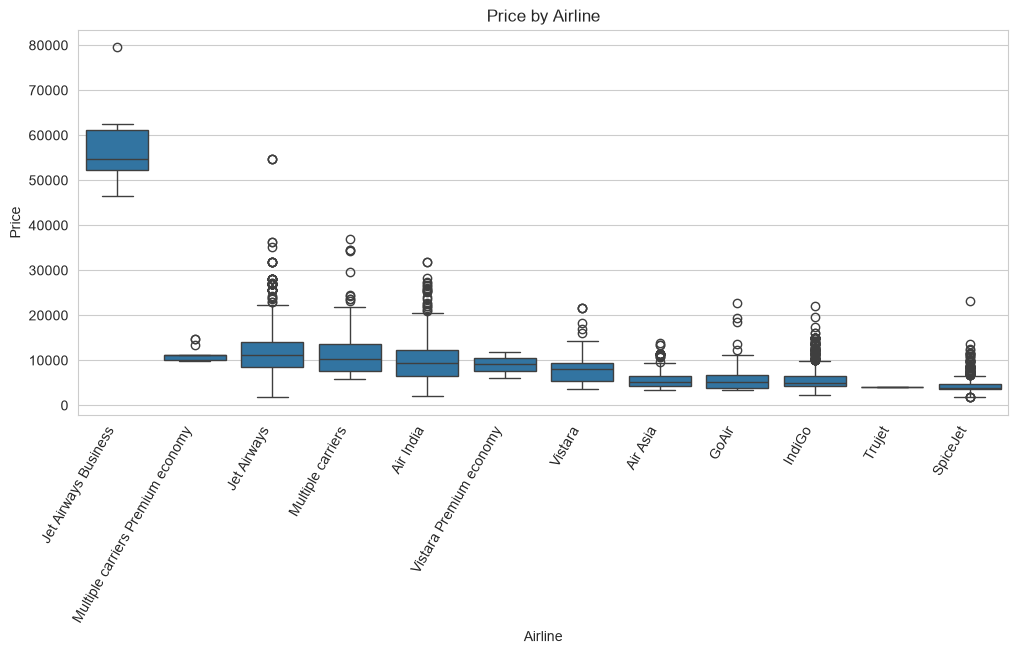

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64


In [15]:
order = data.groupby("Airline")["Price"].median().sort_values(ascending=False).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=data, x="Airline", y="Price", order=order)
plt.xticks(rotation=60, ha="right"); plt.title("Price by Airline"); plt.show()

print(data["Airline"].value_counts())

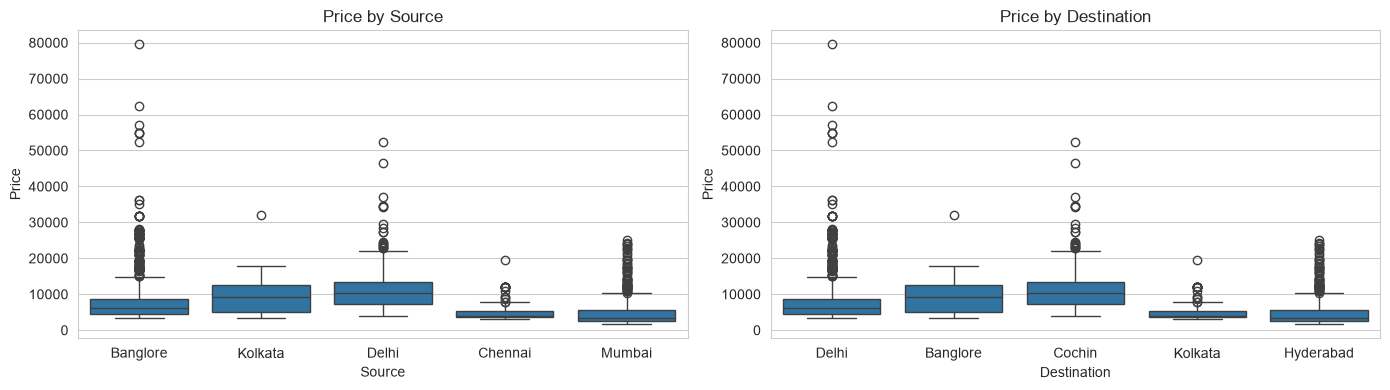

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=data, x="Source", y="Price", ax=ax[0]);            ax[0].set_title("Price by Source")
sns.boxplot(data=data, x="Destination", y="Price", ax=ax[1]);       ax[1].set_title("Price by Destination")
plt.tight_layout(); plt.show()

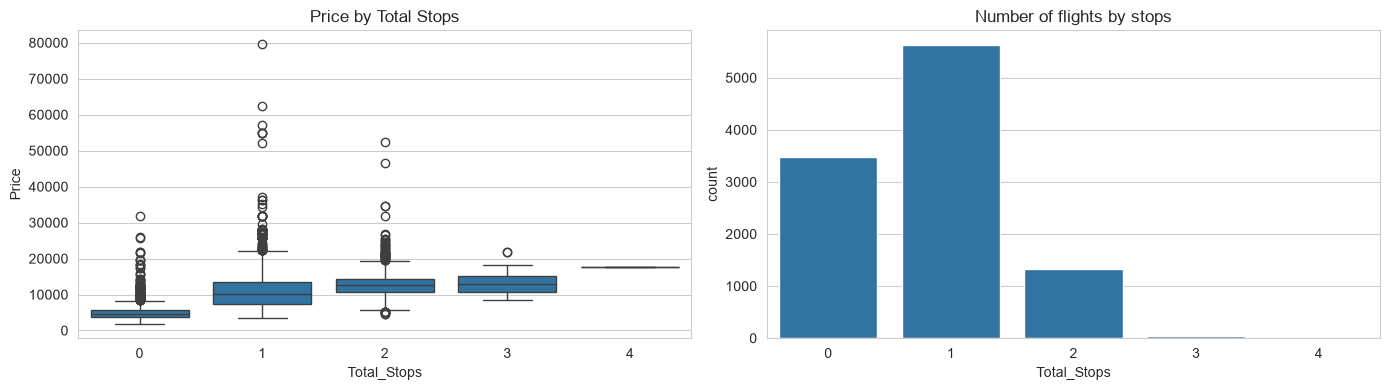

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=data, x="Total_Stops", y="Price", ax=ax[0]);       ax[0].set_title("Price by Total Stops")
sns.countplot(data=data, x="Total_Stops", ax=ax[1]);                ax[1].set_title("Number of flights by stops")
plt.tight_layout(); plt.show()

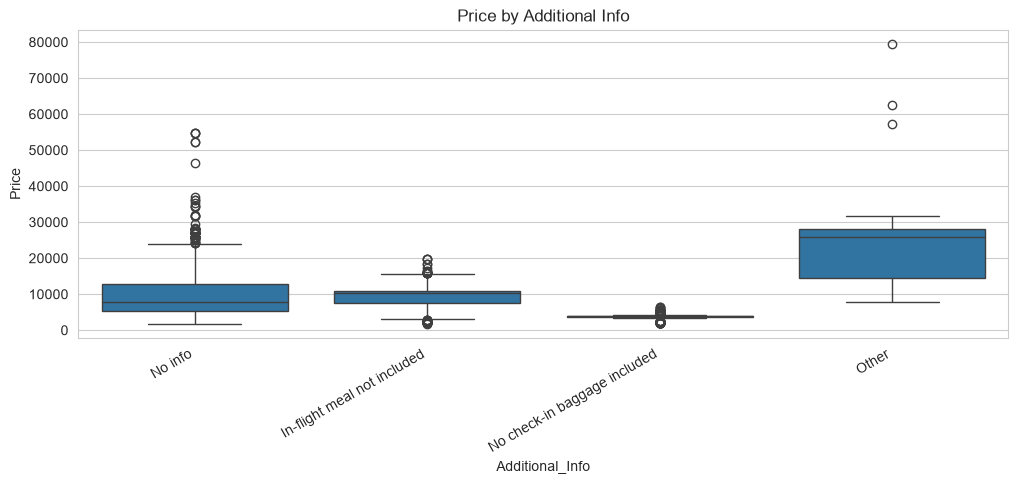

In [18]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=data, x="Additional_Info", y="Price")
plt.xticks(rotation=30, ha="right"); plt.title("Price by Additional Info"); plt.show()

In [ ]:
Date  and  Time features vs price

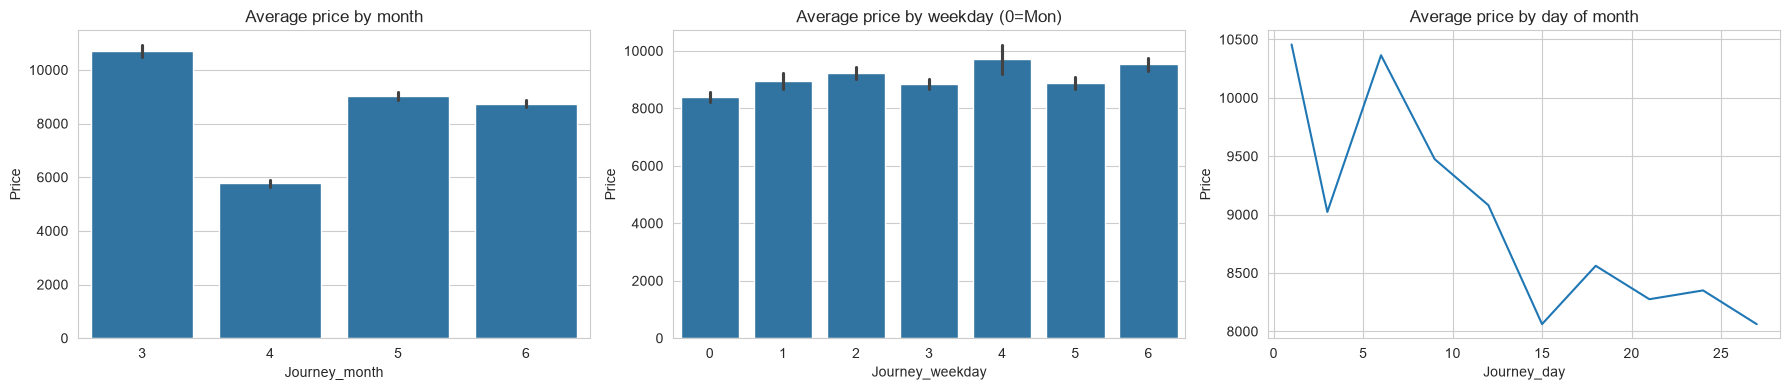

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=data, x="Journey_month", y="Price", ax=ax[0], estimator=np.mean);   ax[0].set_title("Average price by month")
sns.barplot(data=data, x="Journey_weekday", y="Price", ax=ax[1], estimator=np.mean); ax[1].set_title("Average price by weekday (0=Mon)")
sns.lineplot(data=data.groupby("Journey_day")["Price"].mean().reset_index(), x="Journey_day", y="Price", ax=ax[2]); ax[2].set_title("Average price by day of month")
plt.tight_layout(); plt.show()

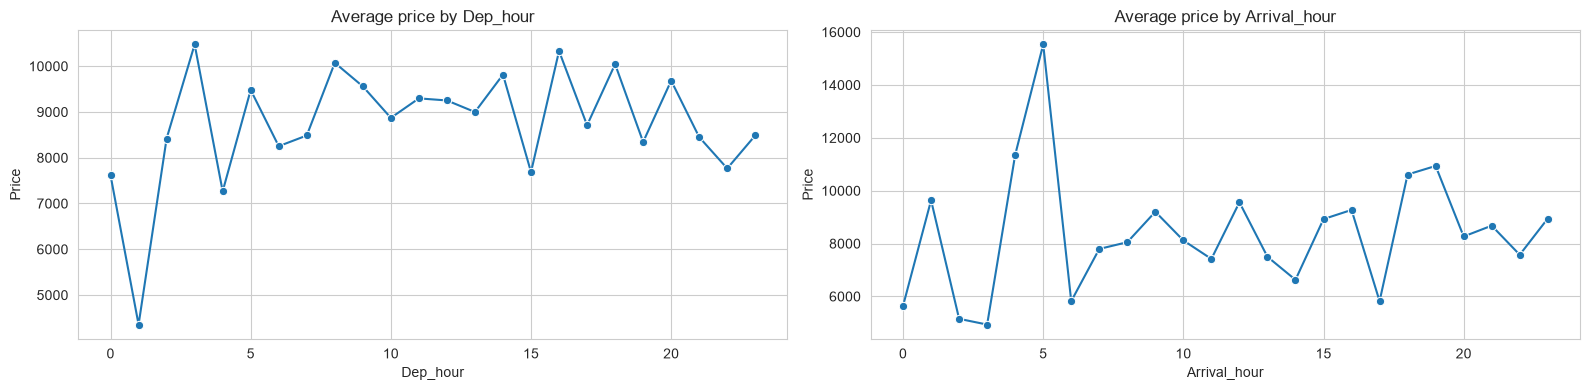

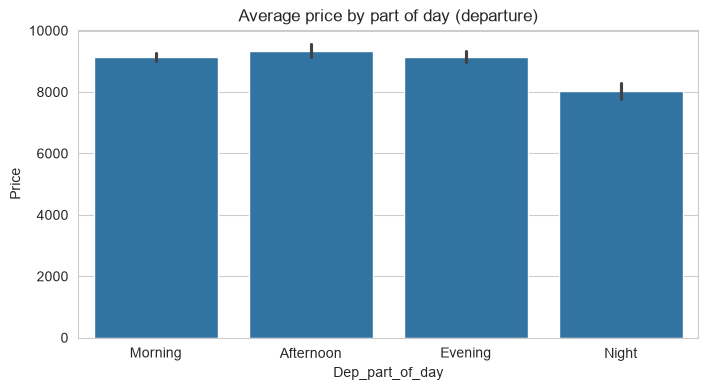

In [20]:
cols = [c for c in ["Dep_hour", "Arrival_hour"] if c in data.columns]
fig, ax = plt.subplots(1, len(cols), figsize=(8 * len(cols), 4))
ax = np.atleast_1d(ax)
for a, c in zip(ax, cols):
    sns.lineplot(data=data.groupby(c)["Price"].mean().reset_index(), x=c, y="Price", marker="o", ax=a)
    a.set_title(f"Average price by {c}")
plt.tight_layout(); plt.show()

if "Dep_part_of_day" in data.columns:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=data, x="Dep_part_of_day", y="Price", order=["Morning", "Afternoon", "Evening", "Night"])
    plt.title("Average price by part of day (departure)"); plt.show()

In [ ]:
Duration vs feature price

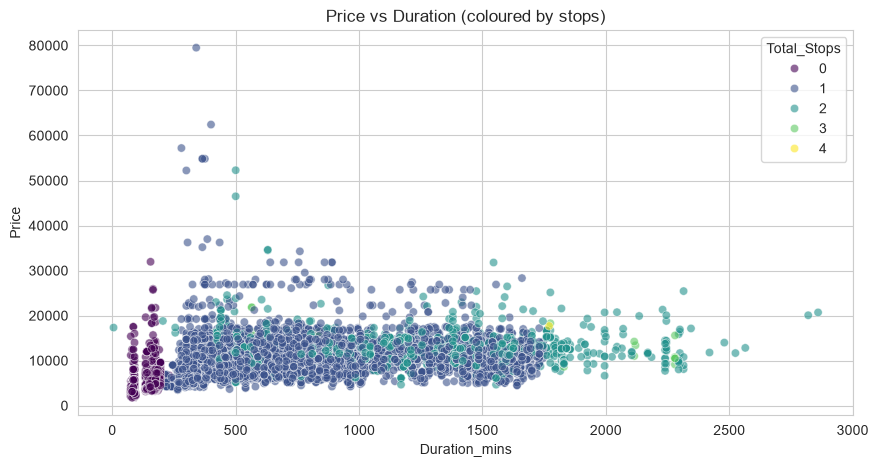

In [21]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x="Duration_mins", y="Price", hue="Total_Stops", palette="viridis", alpha=0.6)
plt.title("Price vs Duration (coloured by stops)"); plt.show()

In [ ]:
Correlation, route popularity and Key tables

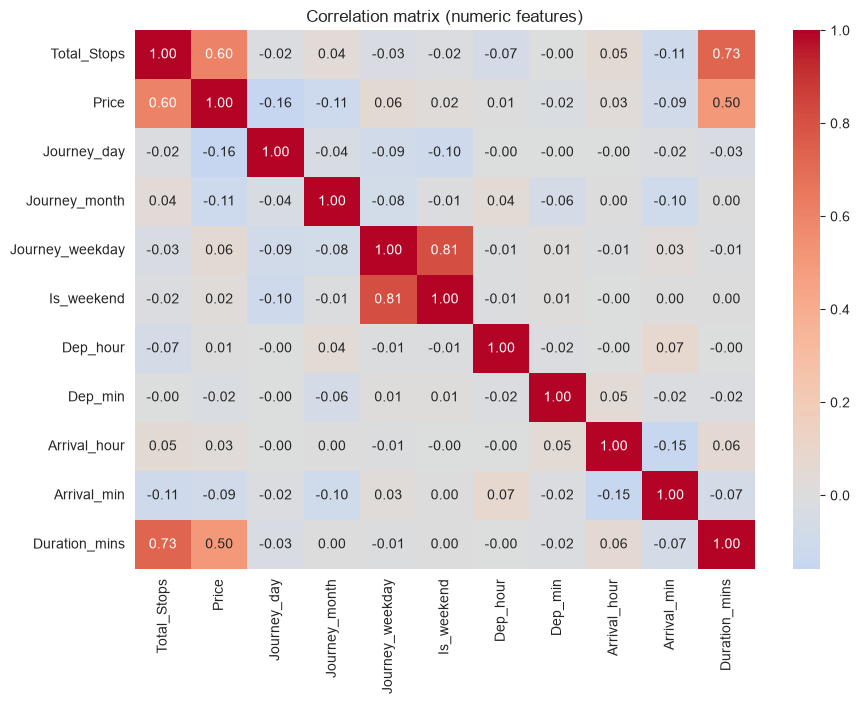

Price              1.000000
Total_Stops        0.602013
Duration_mins      0.501758
Journey_weekday    0.055846
Arrival_hour       0.031023
Is_weekend         0.022130
Dep_hour           0.005155
Dep_min           -0.024155
Arrival_min       -0.086163
Journey_month     -0.113396
Journey_day       -0.159044
Name: Price, dtype: float64


In [22]:
num_cols = data.select_dtypes(include=np.number).columns
plt.figure(figsize=(10, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)"); plt.show()

print(data[num_cols].corr()["Price"].sort_values(ascending=False))

In [23]:
route_tbl = (data.groupby(["Source", "Destination"])["Price"]
                 .agg(flights="count", avg_price="mean", median_price="median")
                 .sort_values("flights", ascending=False).round(0))
display(route_tbl)

# Average price by airline
display(data.groupby("Airline")["Price"].agg(flights="count", avg_price="mean", max_price="max").sort_values("avg_price", ascending=False).round(0))

,,flights,avg_price,median_price
Source,Destination,,,
Delhi,Cochin,4345,10462.0,10262.0
Kolkata,Banglore,2860,9143.0,9345.0
Banglore,Delhi,2179,8023.0,6121.0
Mumbai,Hyderabad,697,5060.0,3342.0
Chennai,Kolkata,381,4790.0,3850.0


,flights,avg_price,max_price
Airline,,,
Jet Airways Business,6,58359.0,79512
Jet Airways,3700,11599.0,54826
Multiple carriers Premium economy,13,11419.0,14629
Multiple carriers,1196,10903.0,36983
Air India,1694,9557.0,31945
Vistara Premium economy,3,8962.0,11793
Vistara,478,7801.0,21730
GoAir,194,5861.0,22794
IndiGo,2043,5668.0,22153


In [ ]:
Data Analysis Report-Summary findings

In [ ]:
Tak-2 Predictive model

In [ ]:
Preprocessing

In [24]:
X = data.drop(columns=["Price"])
y = data["Price"]

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]
print("Categorical:", categorical_cols)
print("Numeric:", numeric_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

Categorical: ['Airline', 'Source', 'Destination', 'Additional_Info', 'Dep_part_of_day']
Numeric: ['Total_Stops', 'Journey_day', 'Journey_month', 'Journey_weekday', 'Is_weekend', 'Dep_hour', 'Dep_min', 'Arrival_hour', 'Arrival_min', 'Duration_mins']
(8369, 15) (2093, 15)


In [25]:
def make_preprocessor(scale=False):
    num_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", num_step, numeric_cols),
    ])

In [ ]:
Build and compare Multiple models

In [26]:
models = {
    "Linear Regression":   (LinearRegression(), True),
    "Ridge":               (Ridge(alpha=1.0), True),
    "Lasso":               (Lasso(alpha=1.0, max_iter=10000), True),
    "KNN":                 (KNeighborsRegressor(n_neighbors=5), True),
    "Decision Tree":       (DecisionTreeRegressor(random_state=RANDOM_STATE), False),
    "Random Forest":       (RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting":   (GradientBoostingRegressor(random_state=RANDOM_STATE), False),
}
if HAS_XGB:
    models["XGBoost"] = (XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                                      random_state=RANDOM_STATE, n_jobs=-1), False)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = [], {}

for name, (model, scale) in models.items():
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", model)])
    pipe.fit(X_train, y_train)
    pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)
    cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)
    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_tr),
        "Test R2": r2_score(y_test, pred_te),
        "CV R2 (mean)": cv.mean(),
        "CV R2 (std)": cv.std(),
        "MAE": mean_absolute_error(y_test, pred_te),
        "RMSE": rmse(y_test, pred_te),
        "MAPE %": np.mean(np.abs((y_test - pred_te) / y_test)) * 100,
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Train R2,Test R2,CV R2 (mean),CV R2 (std),MAE,RMSE,MAPE %
0,Random Forest,0.982,0.887,0.880,0.028,670.683,1538.332,7.670
1,Decision Tree,0.996,0.814,0.792,0.053,787.666,1969.630,8.715
2,Gradient Boosting,0.841,0.806,0.823,0.023,1244.237,2013.543,14.791
3,KNN,0.859,0.757,0.767,0.037,1279.653,2252.916,15.233
4,Ridge,0.691,0.653,0.687,0.016,1786.288,2691.630,22.294
5,Linear Regression,0.692,0.652,0.688,0.018,1785.577,2692.257,22.267
6,Lasso,0.692,0.652,0.688,0.018,1786.088,2692.632,22.277


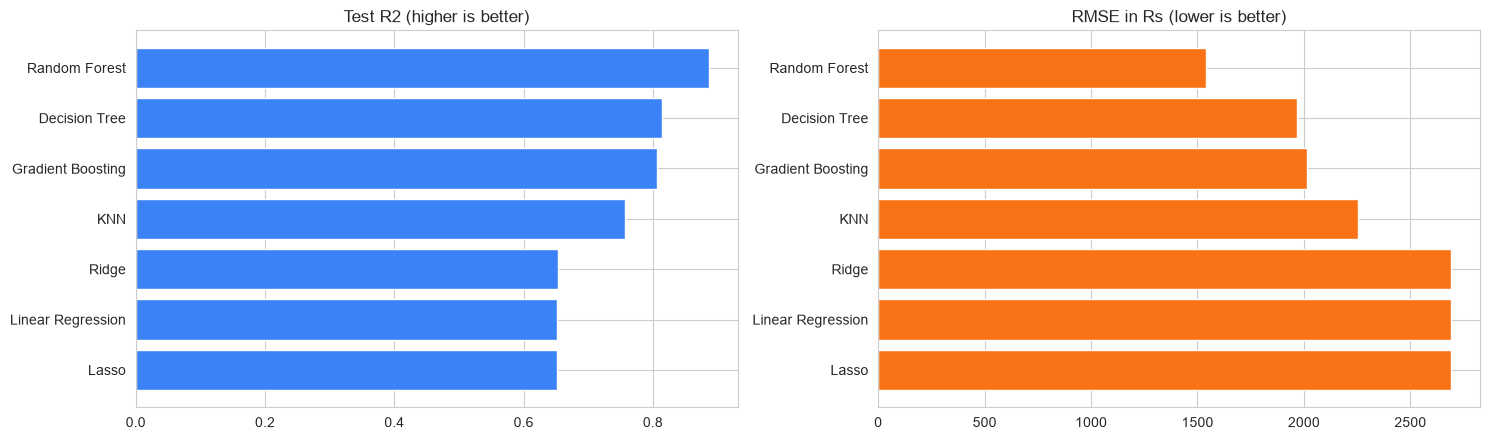

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
plot_df = results_df.sort_values("Test R2")
ax[0].barh(plot_df["Model"], plot_df["Test R2"], color="#3b82f6"); ax[0].set_title("Test R2 (higher is better)")
ax[1].barh(plot_df["Model"], plot_df["RMSE"], color="#f97316");    ax[1].set_title("RMSE in Rs (lower is better)")
plt.tight_layout(); plt.show()

In [ ]:
Hyperparameter Tuning of the best Tree based Models

In [28]:
rf_pipe = Pipeline([("prep", make_preprocessor(False)),
                    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
rf_params = {
    "model__n_estimators":      [200, 300, 500],
    "model__max_depth":         [10, 15, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf":  [1, 2, 4],
    "model__max_features":      ["sqrt", 0.5, 1.0],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=15, cv=3, scoring="r2",
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best RF CV R2 :", round(rf_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best RF params: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 20}
Best RF CV R2 : 0.8738


In [29]:
if HAS_XGB:
    xgb_pipe = Pipeline([("prep", make_preprocessor(False)),
                         ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
    xgb_params = {
        "model__n_estimators":     [200, 400, 600],
        "model__learning_rate":    [0.03, 0.05, 0.1],
        "model__max_depth":        [4, 6, 8, 10],
        "model__subsample":        [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
    }
    xgb_search = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=15, cv=3, scoring="r2",
                                    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
    xgb_search.fit(X_train, y_train)
    print("Best XGB params:", xgb_search.best_params_)
    print("Best XGB CV R2 :", round(xgb_search.best_score_, 4))

In [30]:
tuned = {"Random Forest (tuned)": rf_search.best_estimator_}
if HAS_XGB:
    tuned["XGBoost (tuned)"] = xgb_search.best_estimator_

tuned_rows = []
for name, pipe in tuned.items():
    p = pipe.predict(X_test)
    tuned_rows.append({"Model": name, "Test R2": r2_score(y_test, p), "MAE": mean_absolute_error(y_test, p),
                       "RMSE": rmse(y_test, p), "MAPE %": np.mean(np.abs((y_test - p) / y_test)) * 100})
    fitted[name] = pipe

tuned_df = pd.DataFrame(tuned_rows)
tuned_df.round(3)

,Model,Test R2,MAE,RMSE,MAPE %
0,Random Forest (tuned),0.889,664.67,1519.351,7.598


In [ ]:
Can a log transformed target help?

In [33]:
# Price is skewed. Train on log(Price), then convert predictions back with exp().
best_rf_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
log_pipe = Pipeline([("prep", make_preprocessor(False)),
                     ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **best_rf_params))])
log_pipe.fit(X_train, np.log1p(y_train))
p_log = np.expm1(log_pipe.predict(X_test))

print(f"Log-target RF -> R2: {r2_score(y_test, p_log):.4f} | MAE: {mean_absolute_error(y_test, p_log):,.0f} | RMSE: {rmse(y_test, p_log):,.0f}")

Log-target RF -> R2: 0.8925 | MAE: 647 | RMSE: 1,497


In [ ]:
Select  and Evaluate the final model

In [32]:
all_scores = []
for name, pipe in fitted.items():
    p = pipe.predict(X_test)
    all_scores.append({"Model": name, "Test R2": r2_score(y_test, p), "MAE": mean_absolute_error(y_test, p), "RMSE": rmse(y_test, p)})
final_table = pd.DataFrame(all_scores).sort_values("Test R2", ascending=False).reset_index(drop=True)
display(final_table.round(3))

best_name = final_table.loc[0, "Model"]
best_model = fitted[best_name]
print("\nSelected final model:", best_name)

,Model,Test R2,MAE,RMSE
0,Random Forest (tuned),0.889,664.670,1519.351
1,Random Forest,0.887,670.683,1538.332
2,Decision Tree,0.814,787.666,1969.630
3,Gradient Boosting,0.806,1244.237,2013.543
4,KNN,0.757,1279.653,2252.916
5,Ridge,0.653,1786.288,2691.630
6,Linear Regression,0.652,1785.577,2692.257
7,Lasso,0.652,1786.088,2692.632



Selected final model: Random Forest (tuned)


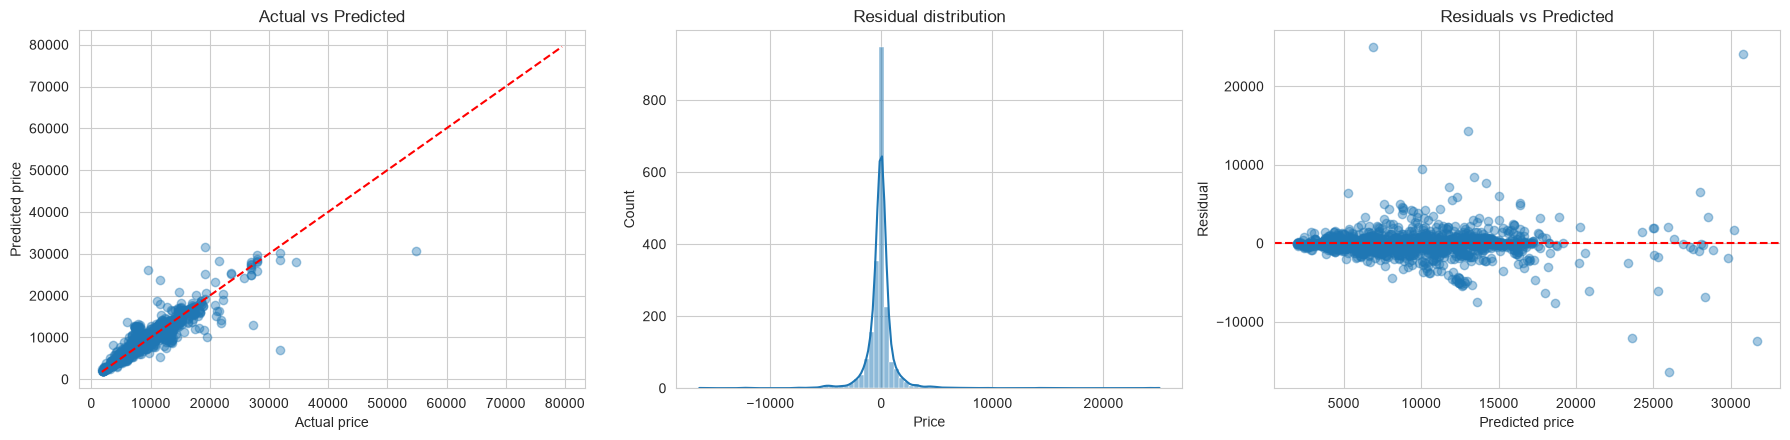

In [34]:
pred = best_model.predict(X_test)
residuals = y_test - pred

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(y_test, pred, alpha=0.4)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title("Actual vs Predicted")
sns.histplot(residuals, kde=True, ax=ax[1]); ax[1].set_title("Residual distribution")
ax[2].scatter(pred, residuals, alpha=0.4); ax[2].axhline(0, color="r", ls="--")
ax[2].set_xlabel("Predicted price"); ax[2].set_ylabel("Residual"); ax[2].set_title("Residuals vs Predicted")
plt.tight_layout(); plt.show()

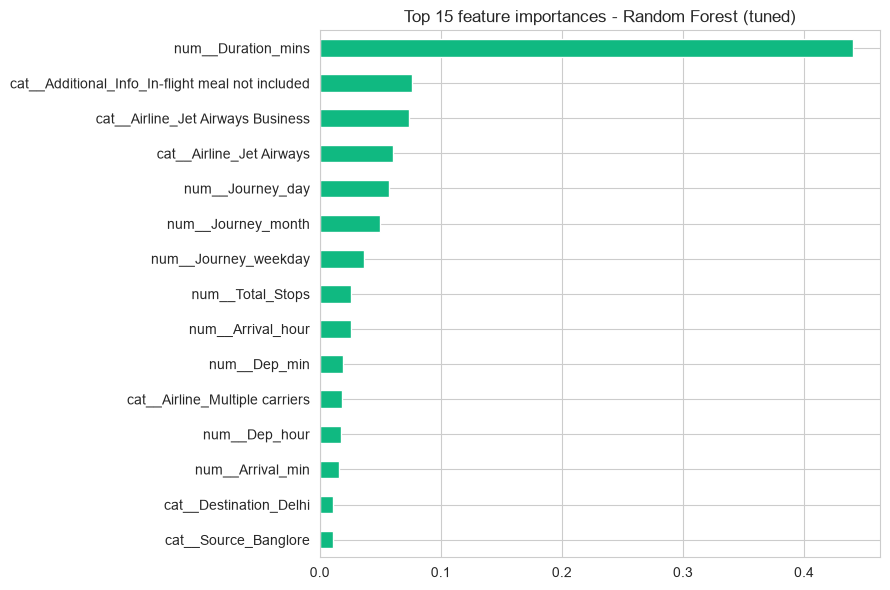

In [37]:
best = best_model.named_steps["model"]
if hasattr(best, "feature_importances_"):
    names = best_model.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(best.feature_importances_, index=names).sort_values(ascending=False).head(15)
    plt.figure(figsize=(9, 6))
    imp[::-1].plot(kind="barh", color="#10b981")
    plt.title(f"Top 15 feature importances - {best_name}"); plt.tight_layout(); plt.show()

In [ ]:
save the model and predict for a new customer

In [38]:
joblib.dump(best_model, "flight_price_model.pkl")
print("Saved -> flight_price_model.pkl")

# Reload and predict on a new journey.
# Values must use the same labels as the training data (e.g. 'Delhi', 'Cochin', 'Banglore').
loaded = joblib.load("flight_price_model.pkl")

def predict_price(airline, source, destination, journey_date, dep_time, arrival_time,
                  duration_mins, total_stops, additional_info="No info"):
    d = pd.to_datetime(journey_date)
    dep_h, dep_m = map(int, dep_time.split(":"))
    arr_h, arr_m = map(int, arrival_time.split(":"))
    row = {
        "Airline": airline, "Source": source, "Destination": destination,
        "Total_Stops": total_stops, "Additional_Info": additional_info,
        "Journey_day": d.day, "Journey_month": d.month, "Journey_weekday": d.dayofweek,
        "Is_weekend": int(d.dayofweek >= 5),
        "Dep_hour": dep_h, "Dep_min": dep_m, "Arrival_hour": arr_h, "Arrival_min": arr_m,
        "Duration_mins": duration_mins, "Dep_part_of_day": part_of_day(dep_h),
    }
    new = pd.DataFrame([row])[X.columns]          # same column order as training
    return float(loaded.predict(new)[0])

example = predict_price("IndiGo", "Banglore", "Delhi", "2019-06-15", "06:00", "08:45", 165, 0)
print(f"Predicted fare: Rs {example:,.0f}")

Saved -> flight_price_model.pkl
Predicted fare: Rs 4,313


In [ ]:
Model comparision and Report

In [39]:
from IPython.display import Markdown
report = final_table.copy()
report[["Test R2", "MAE", "RMSE"]] = report[["Test R2", "MAE", "RMSE"]].round(3)
best = report.iloc[0]; worst = report.iloc[-1]
def to_md(d):
    rows = ["| " + " | ".join(d.columns) + " |", "|" + "---|" * len(d.columns)]
    rows += ["| " + " | ".join(str(v) for v in r) + " |" for r in d.values]
    return "\n".join(rows)
display(Markdown("### Performance of all models on the test set\n\n" + to_md(report)))
display(Markdown(f'''
**Best model for production: {best["Model"]}** (R2 = {best["Test R2"]}, MAE = Rs {best["MAE"]:,.0f}, RMSE = Rs {best["RMSE"]:,.0f}).  
Weakest model: {worst["Model"]} (R2 = {worst["Test R2"]}).
'''))

### Performance of all models on the test set

| Model | Test R2 | MAE | RMSE |
|---|---|---|---|
| Random Forest (tuned) | 0.889 | 664.67 | 1519.351 |
| Random Forest | 0.887 | 670.683 | 1538.332 |
| Decision Tree | 0.814 | 787.666 | 1969.63 |
| Gradient Boosting | 0.806 | 1244.237 | 2013.543 |
| KNN | 0.757 | 1279.653 | 2252.916 |
| Ridge | 0.653 | 1786.288 | 2691.63 |
| Linear Regression | 0.652 | 1785.577 | 2692.257 |
| Lasso | 0.652 | 1786.088 | 2692.632 |


**Best model for production: Random Forest (tuned)** (R2 = 0.889, MAE = Rs 665, RMSE = Rs 1,519).  
Weakest model: Lasso (R2 = 0.652).
